# NumPy — dimensions, summaries, and images

Interpret each array dimension before selecting data or calculating a summary. Behavioural demonstrations use invented sessions with 20 trials each.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Rows and columns

Each row is one session. Each column is a trial position within a session. A shape of `(4, 20)` means four sessions and 20 trials per session.

In [2]:
session_outcomes = np.array([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0]])
print(session_outcomes.shape)
print(session_outcomes[1, :])
print(session_outcomes[:, 0])

(4, 20)
[0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
[1 0 1 1]


**Predict:** how many values are in `session_outcomes[2, :]`? What does `session_outcomes[2, 0]` refer to?

**Work backwards:** select the first three trials of the last session.

In [3]:
# Write the selection.

## Summarise along an axis

`axis=1` averages over the trial dimension, leaving one value for each session. `axis=0` averages over the session dimension, leaving one value for each trial position. The named axis is the dimension being reduced.

In [4]:
session_accuracy = np.mean(session_outcomes, axis=1)
trial_position_accuracy = np.mean(session_outcomes, axis=0)
print(session_accuracy, session_accuracy.shape)
print(trial_position_accuracy.shape)

[0.7  0.75 0.8  0.9 ] (4,)
(20,)


**Ask:** predict the shape before using `np.sum(session_outcomes, axis=1)`. Which result would let you check the first session by hand? Why does `np.mean(session_outcomes)` give only one number?

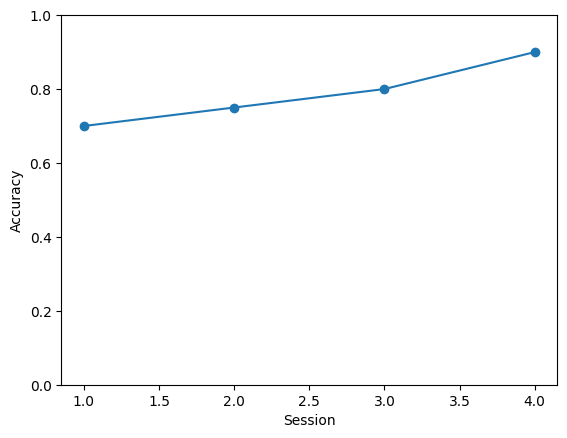

In [5]:
plt.plot(np.arange(1, 5), session_accuracy, "o-")
plt.xlabel("Session")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

## A rectangular region of an array

The first index selects rows (vertical position); the second selects columns (horizontal position). The stop of each slice is excluded.

In [6]:
grid = np.array([[0, 1, 2, 3, 4], [10, 11, 12, 13, 14], [20, 21, 22, 23, 24], [30, 31, 32, 33, 34]])
print(grid[1:3, 2:5])

[[12 13 14]
 [22 23 24]]


**Predict:** which values are in `grid[0:2, 1:3]`?

**Work backwards:** write the slice that produces `[[21, 22], [31, 32]]`.

In [7]:
# Select the requested rectangle.

## Load and plot an actual image

The supplied image is a photograph of a cup of coffee. `plt.imread` loads the image file into a NumPy array. `plt.imshow` displays that array as an image rather than an x/y line plot.

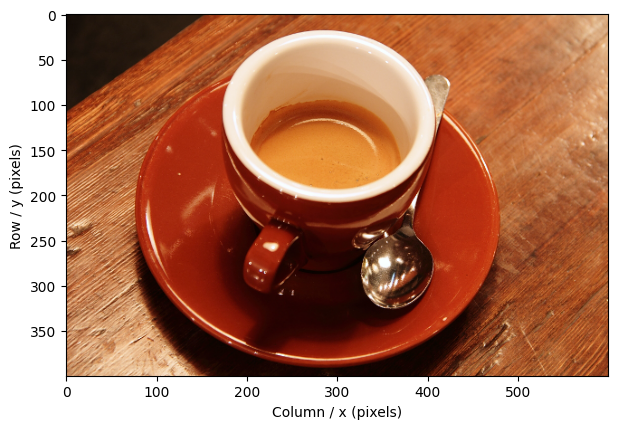

(400, 600, 3)


In [8]:
image = plt.imread("assets/coffee.png")
plt.figure(figsize=(7, 5))
plt.imshow(image)
plt.xlabel("Column / x (pixels)")
plt.ylabel("Row / y (pixels)")
plt.show()
print(image.shape)

## What do the dimensions mean?

The shape is **(400, 600, 3)**:

- **400 rows**: the image height, along axis 0;
- **600 columns**: the image width, along axis 1;
- **3 colour channels**: red, green, and blue, along axis 2.

One pixel therefore has three colour values. The top-left pixel is at row 0, column 0. Rows increase downwards; columns increase to the right. Array indexing follows the order **row, column, channel**.